# Problem 2: Latent-variable inference in a tiny language model
## Group Members :

Lakshya Arukiya (240589) 

Priyanshu Verma (240811)

Arpit Kumar Singh (240194)

Chirag Gupta (240311)

Saurabh Raj (240947)

In [1]:
import os, json
os.environ['OMP_NUM_THREADS']='4'
os.environ['OPENBLAS_NUM_THREADS']='4'
import torch
torch.set_num_threads(4)
from scipy.special import logsumexp
print('PyTorch:',torch.__version__,'| execution device: CPU | threads:',torch.get_num_threads())

PyTorch: 2.8.0 | execution device: CPU | threads: 4


device: cpu


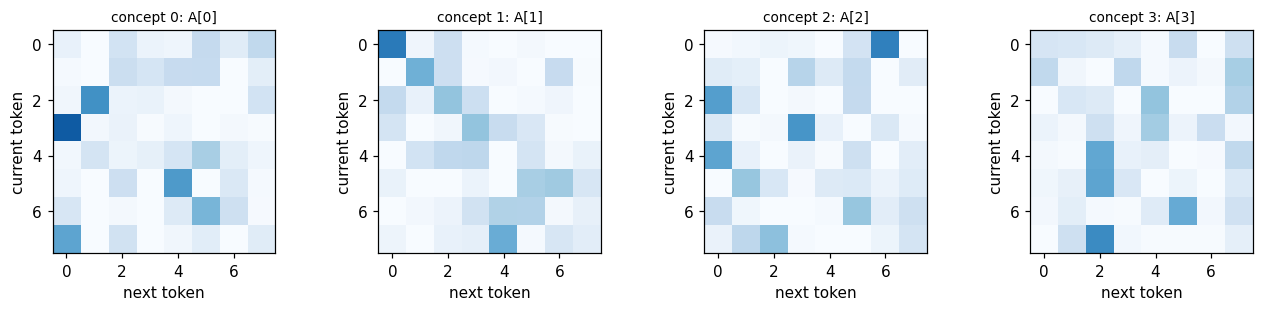

concept 0: 4 6 5 2 7 7 0 7 0 5 6 0 0 7 0 2 7 0 7 0 2 1 5 2 7 5 6 5 4 7 0 7 0 0 5 6 6 5 4 6
concept 1: 4 3 3 5 5 5 7 4 3 4 1 4 7 4 1 1 2 3 3 4 2 0 0 0 2 3 5 6 4 1 6 4 3 0 5 5 7 6 5 5
concept 2: 1 4 0 6 5 2 5 5 7 0 6 0 2 0 3 3 6 6 7 2 0 6 7 2 3 1 5 2 1 5 6 0 5 1 5 1 5 5 7 7
concept 3: 2 1 3 2 4 2 1 7 2 1 7 2 4 2 7 2 7 2 4 2 1 3 5 2 2 4 2 4 2 4 2 4 2 7 2 4 2 2 7 2


In [2]:
import time, math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.linear_model import Ridge

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

V, K, T = 8, 4, 64                                   # vocabulary size, number of concepts, sequence length
rng = np.random.default_rng(0)
A = rng.dirichlet(0.3 * np.ones(V), size=(K, V))     # A[k, a, b] = p(next token b | current token a, concept k)
LOG_PRIOR = np.log(np.full(K, 1.0 / K))              # concepts are equally likely

def sample_sequences(n, A, rng):
    """Draws n sequences: concept z ~ uniform, first token ~ uniform, then the Markov chain A[z]. Returns X (n, T), z (n,)."""
    z = rng.integers(0, len(A), n)
    X = np.zeros((n, T), dtype=np.int64)
    X[:, 0] = rng.integers(0, V, n)
    for t in range(1, T):
        P = A[z, X[:, t - 1]]
        X[:, t] = (P.cumsum(1) < rng.random((n, 1))).sum(1).clip(max=V - 1)
    return X, z

X_train, z_train = sample_sequences(20000, A, rng)
X_test, z_test = sample_sequences(2000, A, rng)

fig, axes = plt.subplots(1, K, figsize=(12, 2.8))
for k in range(K):
    axes[k].imshow(A[k], cmap='Blues', vmin=0, vmax=1); axes[k].set_title(f'concept {k}: A[{k}]', fontsize=9)
    axes[k].set_xlabel('next token'); axes[k].set_ylabel('current token'); axes[k].grid(False)
plt.tight_layout(); plt.show()
for k in range(K):
    print(f'concept {k}:', ' '.join(map(str, X_test[z_test == k][0][:40])))

## Part 1: Inference
For each prefix, $\ell_k=\log\pi_k+\sum_{s=2}^t\log A_k[x_{s-1},x_s]$. We normalise these scores in log-space and use the resulting posterior probabilities to weight the transition rows.

In [3]:
def concept_log_posterior(X,A,log_prior):
    n,t=X.shape
    scores=np.broadcast_to(log_prior,(n,t,len(A))).copy()
    trans=np.log(A[:,X[:,:-1],X[:,1:]]).transpose(1,2,0)
    scores[:,1:]+=np.cumsum(trans,axis=1)
    return scores-logsumexp(scores,axis=-1,keepdims=True)

def bayes_predictive(X,A,log_post):
    rows=A[:,X[:,:-1],:].transpose(1,2,0,3)
    return (np.exp(log_post[:,:-1,:,None])*rows).sum(2)

def per_position_ce(P,X):
    p_true=np.take_along_axis(P,X[:,1:,None],axis=2)[...,0]
    return -np.log(np.maximum(p_true,1e-300)).mean(0)

In [4]:
# Tests
L = concept_log_posterior(X_test[:5], A, LOG_PRIOR)
assert L.shape == (5, T, K) and np.allclose(np.exp(L).sum(-1), 1)
assert np.allclose(L[:, 0], LOG_PRIOR)
x = X_test[0, :6]                                       # brute force on one short prefix
brute = np.log(0.25) + sum(np.log(A[:, x[s - 1], x[s]]) for s in range(1, 6))
brute -= np.log(np.exp(brute).sum())
assert np.allclose(L[0, 5], brute)
P = bayes_predictive(X_test[:5], A, L)
assert P.shape == (5, T - 1, V) and np.allclose(P.sum(-1), 1)
print('Part 1 functions: OK')

Part 1 functions: OK


### Prediction before execution
We expect identification within roughly 8 tokens: sparse transition rows provide strong evidence, but ambiguous transitions delay some sequences.

Median first >95% prefix length: 5.0 | mean mass first >95%: 7


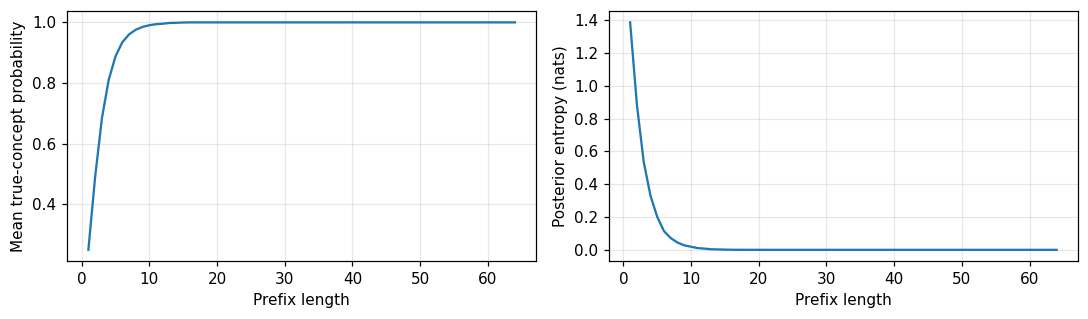

In [5]:
L_all=concept_log_posterior(X_test,A,LOG_PRIOR)
post=np.exp(L_all)
true_mass=np.take_along_axis(post,z_test[:,None,None],axis=2)[...,0]
entropy=-(post*L_all).sum(-1).mean(0)
reached=true_mass>.95
first=np.where(reached.any(1),reached.argmax(1)+1,T+1)
print('Median first >95% prefix length:',np.median(first),'| mean mass first >95%:',np.flatnonzero(true_mass.mean(0)>.95)[0]+1)
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(np.arange(1,T+1),true_mass.mean(0)); axes[0].set(xlabel='Prefix length',ylabel='Mean true-concept probability')
axes[1].plot(np.arange(1,T+1),entropy); axes[1].set(xlabel='Prefix length',ylabel='Posterior entropy (nats)')
plt.tight_layout(); plt.show()

## Part 2: EM derivation
$$Q=\sum_{n,k}r_{nk}\left[\log\pi_k+\sum_{a,b}c_n[a,b]\log A_k[a,b]\right]+\text{constant}.$$
Adding $\beta\sum_{k,a,b}\log A_k[a,b]$ gives a symmetric Dirichlet$(1+\beta)$ MAP objective. The smoothed transition count is $N_{kab}=\beta+\sum_n r_{nk}c_n[a,b]$ and the effective number of sequences in component $k$ is $R_k=\sum_n r_{nk}$. With multipliers for each row and the mixture weights, stationarity gives $N_{kab}/A_k[a,b]=\lambda_{ka}$ and $R_k/\pi_k=\mu$. Normalisation gives $\lambda_{ka}=\sum_b N_{kab}$ and $\mu=N$, hence
$$A_k[a,b]=\frac{\beta+\sum_n r_{nk}c_n[a,b]}{V\beta+\sum_{n,b'}r_{nk}c_n[a,b']},\qquad \pi_k=N^{-1}\sum_n r_{nk}.$$
The E-step normalises $\log\pi_k+\sum_{a,b}c_n[a,b]\log A_k[a,b]$. The likelihood recorded below omits the fixed $-\log V$. MAP updates guarantee the penalised objective, not strictly the unpenalised likelihood; the latter is checked numerically.

In [6]:
def transition_counts(X):
    C=np.zeros((len(X),V,V),dtype=np.float64)
    np.add.at(C,(np.arange(len(X))[:,None],X[:,:-1],X[:,1:]),1)
    return C

def em_mixture_of_chains(C,K,n_iter=50,beta=.01,seed=0):
    rng_em=np.random.default_rng(seed)
    pi_k=np.full(K,1/K)
    A_k=rng_em.dirichlet(np.ones(V),size=(K,V))
    history=[]
    flat=C.reshape(len(C),-1)
    for _ in range(n_iter):
        scores=flat@np.log(A_k).reshape(K,-1).T+np.log(pi_k)
        norm=logsumexp(scores,axis=1)
        history.append(float(norm.mean()))
        r=np.exp(scores-norm[:,None])
        pi_k=r.mean(0)
        counts=(r.T@flat).reshape(K,V,V)+beta
        A_k=counts/counts.sum(-1,keepdims=True)
    return pi_k,A_k,history

In [7]:
# Tests
C_small = transition_counts(X_test[:3])
assert C_small.shape == (3, V, V) and np.all(C_small.sum((1, 2)) == T - 1)
assert C_small[0, X_test[0, 0], X_test[0, 1]] >= 1
pi_t, A_t, h_t = em_mixture_of_chains(transition_counts(X_train[:2000]), K, n_iter=20)
assert np.allclose(A_t.sum(-1), 1) and np.isclose(pi_t.sum(), 1)
assert np.all(np.diff(h_t) > -1e-6), 'EM decreased the log-likelihood'
print('Part 2 functions: OK')

Part 2 functions: OK


### Prediction before execution
The five starts may reach different local optima. Component numbers should differ because permuting labels leaves the mixture unchanged.

seed 0 final log likelihood (excluding -log V) -86.30883333034438 min increment 0.0
seed 1 final log likelihood (excluding -log V) -86.30883333034438 min increment 0.0
seed 2 final log likelihood (excluding -log V) -86.30883333034438 min increment 0.0
seed 3 final log likelihood (excluding -log V) -94.20097773479155 min increment 8.567926258251646e-06
seed 4 final log likelihood (excluding -log V) -86.30883333034438 min increment 0.0


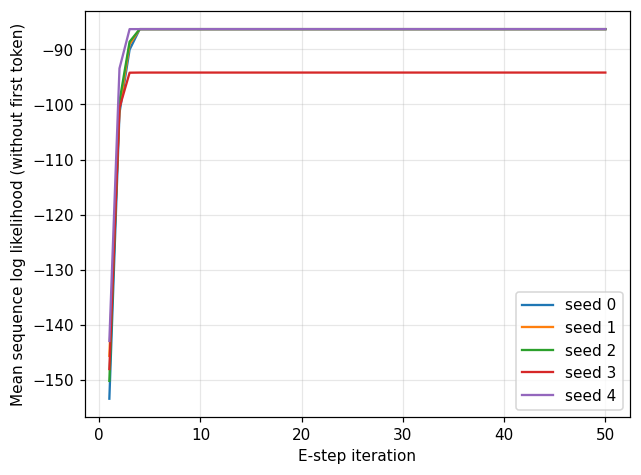

Selected seed: 0 | weights: [0.2488 0.2488 0.2539 0.2485]
learned 0 -> true 1 mean row KL 8.769293245627208e-05
learned 1 -> true 2 mean row KL 0.00013505430888584275
learned 2 -> true 0 mean row KL 0.00010561609018281055
learned 3 -> true 3 mean row KL 0.000173187498385514


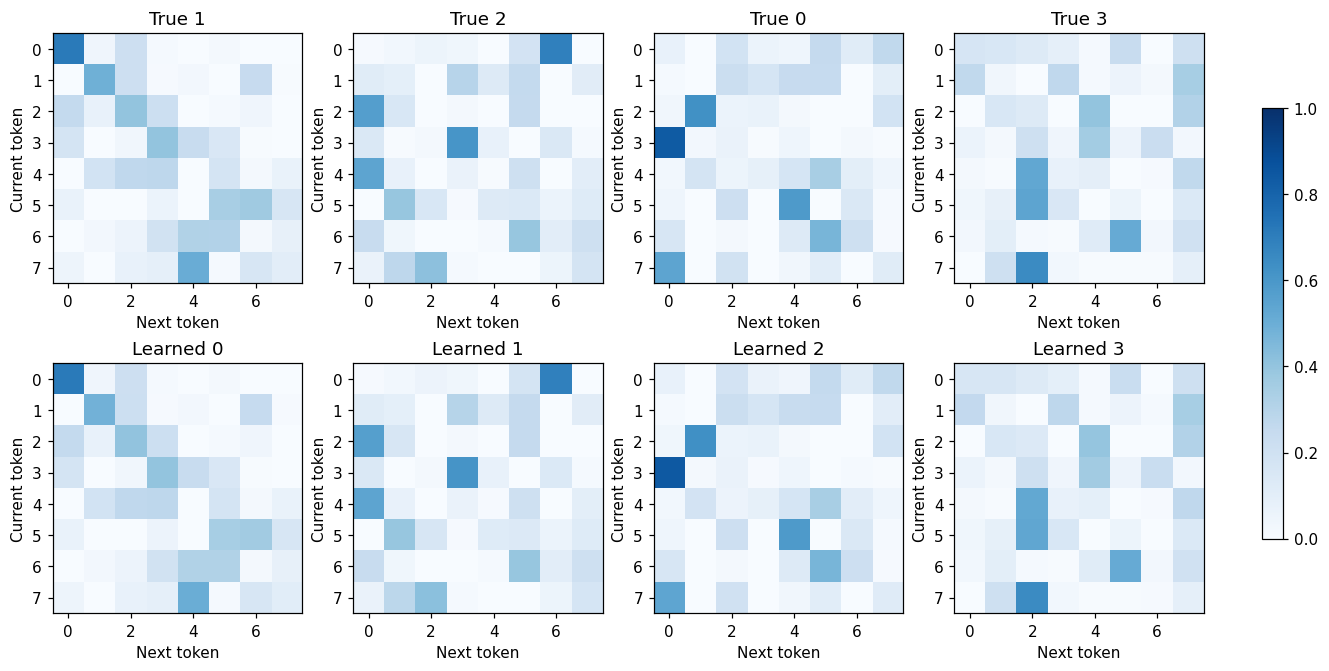

In [8]:
C_train=transition_counts(X_train)
runs=[em_mixture_of_chains(C_train,K,seed=s) for s in range(5)]
def final_ll(run):
    pi,mat,_=run
    return logsumexp(C_train.reshape(len(C_train),-1)@np.log(mat).reshape(K,-1).T+np.log(pi),axis=1).mean()
finals=np.array([final_ll(r) for r in runs])
best=int(finals.argmax()); pi_em,A_em,history=runs[best]
for s,run in enumerate(runs):
    print('seed',s,'final log likelihood (excluding -log V)',finals[s], 'min increment',np.diff(run[2]).min())
    assert np.diff(run[2]).min()>-1e-6
    plt.plot(np.arange(1,51),run[2],label=f'seed {s}')
plt.xlabel('E-step iteration'); plt.ylabel('Mean sequence log likelihood (without first token)'); plt.legend(); plt.show()
# KL(true || learned), averaged equally over source-token rows.
dist=(A[None]*(np.log(A[None])-np.log(A_em[:,None]))).sum(-1).mean(-1)
match=dist.argmin(1)
print('Selected seed:',best,'| weights:',pi_em)
for k in range(K): print('learned',k,'-> true',match[k],'mean row KL',dist[k,match[k]])
assert len(set(match))==K
fig,axes=plt.subplots(2,K,figsize=(12,6),layout="constrained")
for k in range(K):
    for row,mat,label in ((0,A[match[k]],f'True {match[k]}'),(1,A_em[k],f'Learned {k}')):
        im=axes[row,k].imshow(mat,vmin=0,vmax=1,cmap='Blues'); axes[row,k].grid(False); axes[row,k].set(title=label,xlabel='Next token',ylabel='Current token')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.7); plt.show()

### Findings
The median first 95% crossing was 5 tokens; mean mass crossed at 7, earlier than predicted. Four restarts reached -86.3088; seed 3 stopped at -94.2010. Seed 0 was selected. Permuting component labels leaves predictions unchanged; restarts avoided the poorer optimum.

## Part 3: Transformer

In [9]:
class TinyGPT(nn.Module):
    def __init__(self, d=64, layers=2, heads=4):
        super().__init__()
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(T, d)
        block = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(block, layers, enable_nested_tensor=False)
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V)
        self.register_buffer('mask', torch.triu(torch.full((T, T), float('-inf')), 1))

    def hidden(self, x):                                  # (B, t) tokens -> (B, t, d) final hidden states
        t = x.shape[1]
        h = self.tok(x) + self.pos(torch.arange(t, device=x.device))
        return self.ln(self.blocks(h, mask=self.mask[:t, :t], is_causal=True))

    def forward(self, x):                                 # next-token logits
        return self.head(self.hidden(x))

def train_lm(X, steps=2000, batch=128, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    model = TinyGPT().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    Xt = torch.from_numpy(X).to(device)
    gen = torch.Generator(device='cpu').manual_seed(seed)
    t0 = time.time()
    for step in range(steps + 1):
        xb = Xt[torch.randint(0, len(Xt), (batch,), generator=gen).to(device)]
        loss = F.cross_entropy(model(xb[:, :-1]).reshape(-1, V), xb[:, 1:].reshape(-1))
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 500 == 0:
            print(f'step {step:5d}  train cross-entropy {loss.item():.3f}  ({time.time() - t0:.0f}s)')
    return model.eval()

@torch.no_grad()
def lm_predictive(model, X):
    """Next-token distributions of the model, shape (n, T-1, V), as float64 numpy."""
    out = [torch.softmax(model(torch.from_numpy(X[i:i + 500, :-1]).to(device)), -1).double().cpu().numpy()
           for i in range(0, len(X), 500)]
    return np.concatenate(out)

print('parameters:', sum(p.numel() for p in TinyGPT().parameters()))
model = train_lm(X_train)

parameters: 105224
step     0  train cross-entropy 2.135  (0s)
step   500  train cross-entropy 1.400  (14s)
step  1000  train cross-entropy 1.363  (29s)
step  1500  train cross-entropy 1.375  (44s)
step  2000  train cross-entropy 1.366  (59s)


### Prediction before execution
Expected ranking: oracle, Bayes, EM, transformer, bigram. Empirical positions can cross, but Bayes cannot be beaten in expectation. EM benefits from the correct model family.

Oracle         CE=1.346933 perplexity=3.845614
Bayes          CE=1.368938 perplexity=3.931173
EM mixture     CE=1.369042 perplexity=3.931582
Transformer    CE=1.384915 perplexity=3.994485
Bigram         CE=1.817777 perplexity=6.158152


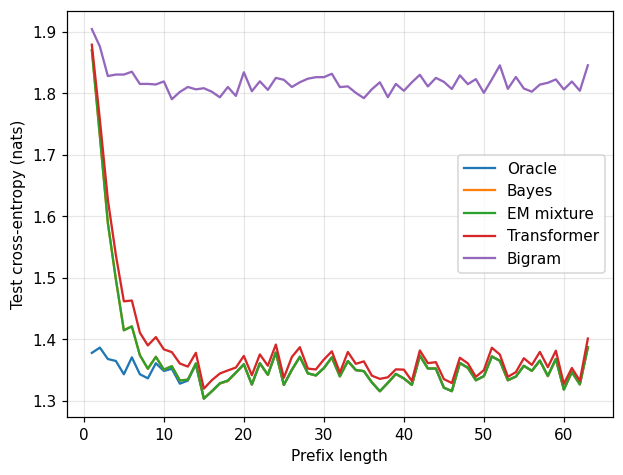

EM free parameters: 227 | stored entries: 260
Transformer parameters: 105224


In [10]:
P_bayes=bayes_predictive(X_test,A,L_all)
P_em=bayes_predictive(X_test,A_em,concept_log_posterior(X_test,A_em,np.log(pi_em)))
P_lm=lm_predictive(model,X_test)
B=C_train.sum(0)+1; B/=B.sum(1,keepdims=True)
P_bigram=B[X_test[:,:-1]]
P_oracle=A[z_test[:,None],X_test[:,:-1]]
predictors={'Oracle':P_oracle,'Bayes':P_bayes,'EM mixture':P_em,'Transformer':P_lm,'Bigram':P_bigram}
metrics={}
for name,P in predictors.items():
    ce=per_position_ce(P,X_test); metrics[name]=[float(ce.mean()),float(np.exp(ce.mean()))]
    print(f'{name:14s} CE={ce.mean():.6f} perplexity={np.exp(ce.mean()):.6f}')
    plt.plot(np.arange(1,T),ce,label=name)
plt.xlabel('Prefix length'); plt.ylabel('Test cross-entropy (nats)'); plt.legend(); plt.show()
print('EM free parameters:',K*V*(V-1)+K-1,'| stored entries:',K*V*V+K)
print('Transformer parameters:',sum(p.numel() for p in model.parameters()))

### Interpretation
$$\mathbb E[-\log q(X_{t+1}\mid X_{1:t})]=\mathbb E[H(p_B)]+\mathbb E[\mathrm{KL}(p_B\Vert q)].$$
This follows by adding and subtracting $\sum_v p_B(v)\log p_B(v)$. Nonnegative KL rules out beating Bayes in expectation; finite-sample crossings are possible. The oracle's early advantage vanishes as the concept becomes identifiable. Bigram loses context-dependent concept information. EM is closer to Bayes with 227 free parameters versus 105224 transformer parameters: it has the unfair advantage of the correct generative family. The transformer had lower empirical loss at 0 of 63 positions versus Bayes and 0 versus EM.

## Part 4: Predictive distributions

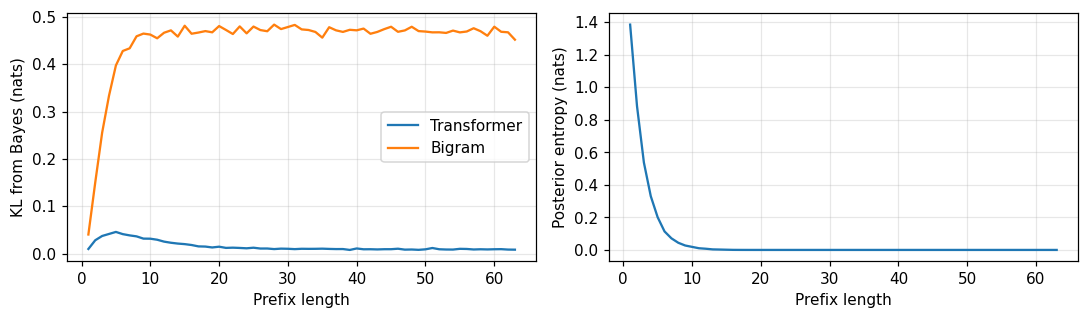

Peak transformer KL prefix: 5 value: 0.04575389468568717 mean: 0.015138703099847306


In [11]:
def kl_per_position(P, Q):
    return (P * (np.log(np.maximum(P, 1e-300)) - np.log(np.maximum(Q, 1e-300)))).sum(-1).mean(0)


kl_lm=kl_per_position(P_bayes,P_lm)
kl_big=kl_per_position(P_bayes,P_bigram)
assert kl_lm.min()>-1e-12 and kl_big.min()>-1e-12
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(np.arange(1,T),kl_lm,label='Transformer'); axes[0].plot(np.arange(1,T),kl_big,label='Bigram'); axes[0].legend(); axes[0].set(xlabel='Prefix length',ylabel='KL from Bayes (nats)')
axes[1].plot(np.arange(1,T),entropy[:-1]); axes[1].set(xlabel='Prefix length',ylabel='Posterior entropy (nats)')
plt.tight_layout(); plt.show()
print('Peak transformer KL prefix:',kl_lm.argmax()+1,'value:',kl_lm.max(),'mean:',kl_lm.mean())

### Interpretation
Transformer KL peaks at prefix 5 (0.0458 nats), averaging 0.0151. At the first token the prior is uniform. A few transitions later the model has to distinguish competing explanations for the same prefix, which may account for the peak. Later the entropy and KL both fall. The prefix plays the role of the prompt. Its transitions change the inferred concept while the network weights stay fixed.

## Part 5: Prediction before execution
Trained states should give the highest R²; random states retain some context, while embeddings capture token/position correlations.

In [12]:
@torch.no_grad()
def hidden_states(model, X, embeddings_only=False):
    x = torch.from_numpy(X).to(device)
    if embeddings_only:
        h = model.tok(x) + model.pos(torch.arange(X.shape[1], device=device))
    else:
        h = model.hidden(x)
    return h.cpu().numpy()

# Batch extraction changes only analysis memory use, not the supplied model.
def collect_hidden(m,emb=False):
    return np.concatenate([hidden_states(m,X_test[i:i+100],emb) for i in range(0,len(X_test),100)])
torch.manual_seed(1)
random_model=TinyGPT().to(device).eval()
probe_scores={}
Y=post.reshape(-1,K)
cut=1500*T
for name,m,emb in [('Trained',model,False),('Random',random_model,False),('Embeddings',model,True)]:
    H=collect_hidden(m,emb).reshape(-1,64).astype(np.float64)
    probe=Ridge(alpha=1.).fit(H[:cut],Y[:cut])
    predicted=probe.predict(H[cut:]); target=Y[cut:]
    r2=1-((target-predicted)**2).sum()/((target-target.mean(0))**2).sum()
    probe_scores[name]=float(r2)
    print(name,'held-out R²:',r2)
    del H

Trained held-out R²: 0.8176502483050632
Random held-out R²: 0.2532071304913013
Embeddings held-out R²: 0.07444728241831156


### Interpretation
Held-out R² is 0.818 for trained states, 0.253 for random states and 0.074 for embeddings. Random attention already mixes some prefix information. The embedding control isolates token and position correlations, which explain much less variance. Training makes the posterior easier to decode. A causal test would remove the probe directions from the final states and compare the change in prediction KL with the change from equally large perturbations in random directions.

## Part 6: Prediction before execution
On a new chain, the first transformer should resemble four-concept inference more than counting. Diverse training should favour counting, sacrificing familiar-concept efficiency.

Oracle mean CE 1.110422319475718
Four-concept Bayes mean CE 3.464925304325162
Four-concept transformer mean CE 3.4732398281788415
Counting mean CE 1.5432691280088613


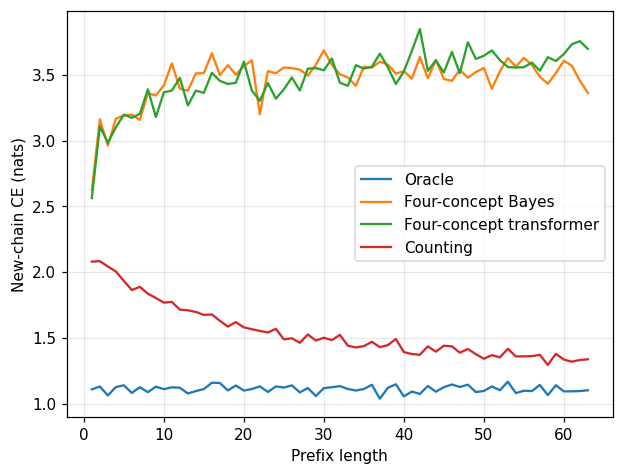

In [13]:
def dirichlet_count_predictive(X,alpha=.3):
    n,t=X.shape
    counts=np.zeros((n,V,V))
    out=np.empty((n,t-1,V))
    ix=np.arange(n)
    for s in range(t-1):
        if s>0: counts[ix,X[:,s-1],X[:,s]]+=1
        row=counts[ix,X[:,s]]+alpha
        out[:,s]=row/row.sum(1,keepdims=True)
    return out

rng_new = np.random.default_rng(123)
A_new = rng_new.dirichlet(0.3 * np.ones(V), size=(1, V))
X_new, _ = sample_sequences(1000, A_new, rng_new)
P_count=dirichlet_count_predictive(X_test)
P_new_count=dirichlet_count_predictive(X_new)
assert np.allclose(P_new_count.sum(-1),1) and np.allclose(P_new_count[:,0],1/V)
# Prefix-only check: changing unseen tokens cannot change an earlier prediction.
changed=X_new[:3].copy(); changed[:,10:]=(changed[:,10:]+1)%V
assert np.allclose(dirichlet_count_predictive(changed)[:,:10],P_new_count[:3,:10])
P_new_bayes=bayes_predictive(X_new,A,concept_log_posterior(X_new,A,LOG_PRIOR))
P_new_lm=lm_predictive(model,X_new)
P_new_oracle=A_new[0,X_new[:,:-1]]
for name,P in [('Oracle',P_new_oracle),('Four-concept Bayes',P_new_bayes),('Four-concept transformer',P_new_lm),('Counting',P_new_count)]:
    ce=per_position_ce(P,X_new)
    print(name,'mean CE',ce.mean()); plt.plot(np.arange(1,T),ce,label=name)
plt.xlabel('Prefix length'); plt.ylabel('New-chain CE (nats)'); plt.legend(); plt.show()

### Diverse pretraining
Each sequence has an independently drawn chain.

In [14]:
def sample_fresh_chains(n, rng):
    As = rng.dirichlet(0.3 * np.ones(V), size=(n, V))
    X = np.zeros((n, T), dtype=np.int64); X[:, 0] = rng.integers(0, V, n)
    for t in range(1, T):
        P = As[np.arange(n), X[:, t - 1]]
        X[:, t] = (P.cumsum(1) < rng.random((n, 1))).sum(1).clip(max=V - 1)
    return X

X_diverse = sample_fresh_chains(20000, np.random.default_rng(7))
model_diverse = train_lm(X_diverse)

step     0  train cross-entropy 2.173  (0s)
step   500  train cross-entropy 1.651  (14s)
step  1000  train cross-entropy 1.642  (28s)
step  1500  train cross-entropy 1.622  (42s)
step  2000  train cross-entropy 1.611  (57s)


New chain Oracle 1.110422319475718
New chain Four-concept Bayes 3.464925304325162
New chain Four-concept transformer 3.4732398281788415
New chain Counting 1.5432691280088613
New chain Diverse transformer 1.5539294746234507
Original concepts Oracle 1.3469331645527582
Original concepts Four-concept Bayes 1.3689378369514853
Original concepts Four-concept transformer 1.3849145365872197
Original concepts Counting 1.7448109510040195
Original concepts Diverse transformer 1.757036086344561


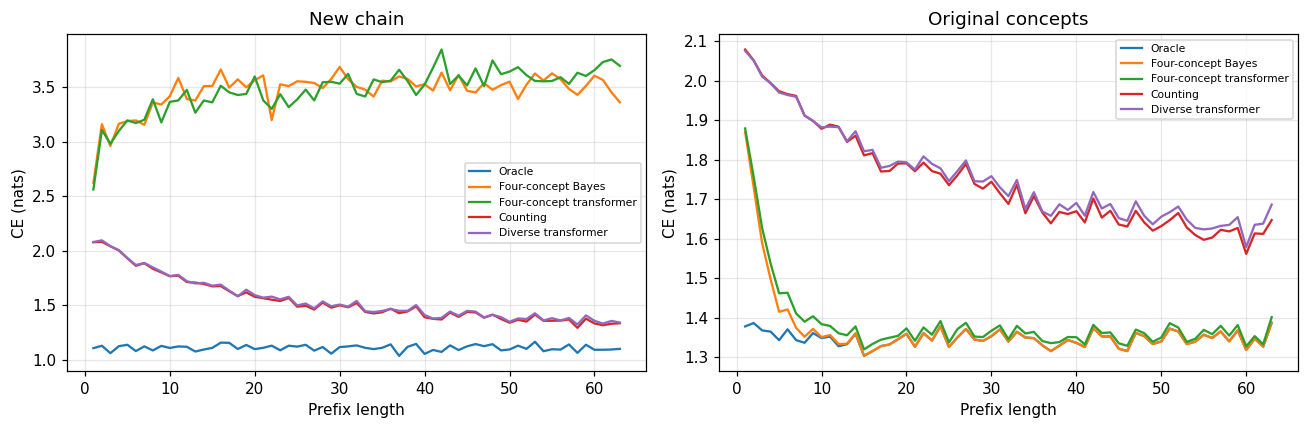

New-chain distributional comparisons: {'Four-model to four-Bayes': 0.609064550607058, 'Four-model to counting': 1.6116934899696362, 'Diverse-model to counting': 0.01284465647670108}


In [15]:
P_div_new=lm_predictive(model_diverse,X_new)
P_div_test=lm_predictive(model_diverse,X_test)
diverse_metrics={}
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,label,X,items in [(axes[0],'New chain',X_new,{'Oracle':P_new_oracle,'Four-concept Bayes':P_new_bayes,'Four-concept transformer':P_new_lm,'Counting':P_new_count,'Diverse transformer':P_div_new}),(axes[1],'Original concepts',X_test,{'Oracle':P_oracle,'Four-concept Bayes':P_bayes,'Four-concept transformer':P_lm,'Counting':P_count,'Diverse transformer':P_div_test})]:
    diverse_metrics[label]={}
    for name,P in items.items():
        ce=per_position_ce(P,X); diverse_metrics[label][name]=float(ce.mean())
        ax.plot(np.arange(1,T),ce,label=name); print(label,name,ce.mean())
    ax.set(title=label,xlabel='Prefix length',ylabel='CE (nats)'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
new_kl={'Four-model to four-Bayes':float(kl_per_position(P_new_bayes,P_new_lm).mean()),'Four-model to counting':float(kl_per_position(P_new_count,P_new_lm).mean()),'Diverse-model to counting':float(kl_per_position(P_new_count,P_div_new).mean())}
print('New-chain distributional comparisons:',new_kl)
results={'median_identification':float(np.median(first)),'mean_identification':int(np.flatnonzero(true_mass.mean(0)>.95)[0]+1),'final_ll':finals.tolist(),'best_seed':best,'match':match.tolist(),'match_kl':[float(dist[k,match[k]]) for k in range(K)],'metrics':metrics,'probe':probe_scores,'kl_peak':int(kl_lm.argmax()+1),'kl_peak_value':float(kl_lm.max()),'kl_mean':float(kl_lm.mean()),'diverse':diverse_metrics,'new_kl':new_kl,'torch':torch.__version__,'device':device}
with open('problem2_results.json','w') as f: json.dump(results,f,indent=2)
torch.save(model.state_dict(),'model_four.pt'); torch.save(model_diverse.state_dict(),'model_diverse.pt')

### Interpretation
On the new chain, four-concept transformer CE is 3.473 versus 3.465 for four-concept Bayes; diverse-transformer CE is 1.554 versus counting's 1.543. The familiar prior cannot represent the new chain, even after 60 tokens. Diverse training sacrifices original-concept performance (1.757 versus 1.385). Both networks approximate Bayesian prediction under different training priors, with measurable gaps; diversity changes the useful adaptation strategy.

## Reflection
The E-step appeared twice. In prefix inference, each observed prefix was a data point and the responsibilities described uncertainty about its generating concept. In EM, each complete training sequence was a data point; its transition counts determined responsibilities under the current parameter estimates. Those responsibilities then weighted the parameter update. The former changes beliefs within a sequence; the latter learns shared parameters across sequences.

The statement that a language model “learns during inference” depends on what learning means. Here, the weights remain fixed while the hidden representation and predictive distribution change with the prefix. The five-way comparison and posterior probe support adaptation through contextual information, but neither proves that the transformer implements exact Bayesian inference. Its remaining predictive KL measures a real approximation gap.

This world has a tiny vocabulary, fixed-length sequences and a single stationary first-order chain per sequence. Real text has changing topics, long-range structure and ambiguous tasks. Therefore the different-priors experiment illustrates a possible mechanism and the importance of training diversity, rather than establishing a complete explanation of real LLM behaviour.

## Use of AI tools
We used OpenAI Codex as a coding assistant while implementing the required functions and experiments, including latent-variable inference, EM, and the analysis code. We also used it to check the logic of our derivations and interpretations and to help draft the written reflection. Our group designed the analysis, made the predictions and judgements about the results, and reviewed and tested all AI-assisted code and text before submission.